## Lasso Regularization for One vs. Rest and Multinomial Models Using Binned Sleep Hours

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
accuracy_score, f1_score, log_loss,
confusion_matrix, classification_report
)
from sklearn.base import clone

In [30]:
# Import cleaned data
Sleep_clean = pd.read_csv('../01_Kaggle_Cleaning_EDA/sleep_clean.csv')

In [31]:
# Different from the models with no regularization, we will keep 'daytime_fatigue_score'

Sleep_clean = Sleep_clean.drop(columns = ['weekly_sleep_debt_hours', 'sleep_quality_score', 'sleep_quality_category'])

In [32]:
Sleep_clean.columns

Index(['age', 'bedtime_screen_time_minutes', 'total_daily_screen_time_hours',
       'doomscroll_sessions_per_night', 'avg_doomscroll_session_minutes',
       'sleep_hours_per_night', 'sleep_latency_minutes',
       'number_of_night_wakeups', 'caffeine_intake_mg_per_day',
       'anxiety_score', 'stress_score', 'daytime_fatigue_score',
       'number_of_news_apps_used', 'phone_checks_per_night',
       'exercise_minutes_per_day', 'days_since_last_digital_detox', 'gender',
       'occupation_status', 'country_region', 'primary_device_used_at_night',
       'bedtime_routine_type', 'uses_night_mode', 'keeps_phone_in_bedroom',
       'consumes_negative_news_content', 'uses_sleep_tracking_app',
       'doomscroller'],
      dtype='object')

Text(0, 0.5, 'Number of Respondents')

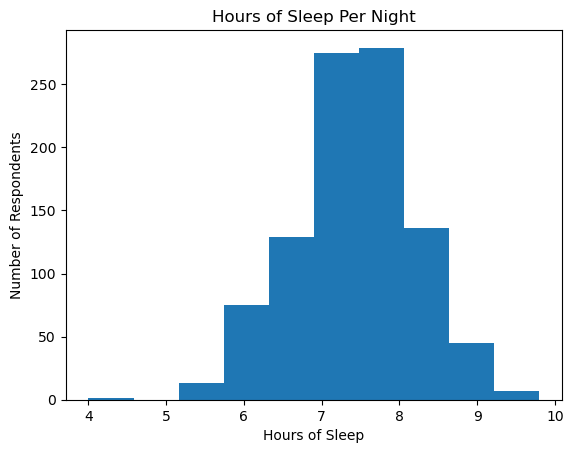

In [33]:
# We create this plot to help justify how we will bin the hours of sleep.
Sleep_clean['sleep_hours_per_night'].value_counts()

plt.hist(Sleep_clean['sleep_hours_per_night'])
plt.title("Hours of Sleep Per Night")
plt.xlabel("Hours of Sleep")
plt.ylabel("Number of Respondents")

We will chose bins of less than 6.5, (6.5, 7], (7, 7.5], (7.5,8], (8, 8.5], and more than 8.5. This allows for a fairly even split of bins while keeping the bin sizes fairly even. See .value_counts() code below.

In [34]:
# Needed to convert it to a string so that OVR would know that it is categories it can classify
sleep_bins = pd.cut(Sleep_clean['sleep_hours_per_night'], bins = [0, 6.5, 7, 7.5, 8, 8.5, 24]).astype('string')
sleep_bins.dtype

string[python]

In [35]:
sleep_bins.value_counts()

sleep_hours_per_night
(7.0, 7.5]     248
(7.5, 8.0]     222
(6.5, 7.0]     167
(0.0, 6.5]     135
(8.0, 8.5]     126
(8.5, 24.0]     62
Name: count, dtype: Int64

The below setup up until the `pipe_ovr` and the `pipe_multi` should be the same as Jack and Maddie's code in order to keep it consistent.

In [36]:
# Outcome vs. predictors separation 
y = sleep_bins
X = Sleep_clean.drop(columns = 'sleep_hours_per_night')

In [37]:
# Train test split (80/20)
# Kept random state the same as the no regularization files to remain comparable
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, stratify = y, random_state = 12
)

In [38]:
# Adding a validation set within the training set
# Again kept the random state the same to keep the validation set comparable
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,        
    stratify=y_train,      
    random_state=12
)

In [39]:
Sleep_clean.dtypes

age                                 int64
bedtime_screen_time_minutes       float64
total_daily_screen_time_hours     float64
doomscroll_sessions_per_night       int64
avg_doomscroll_session_minutes    float64
sleep_hours_per_night             float64
sleep_latency_minutes             float64
number_of_night_wakeups             int64
caffeine_intake_mg_per_day        float64
anxiety_score                       int64
stress_score                        int64
daytime_fatigue_score               int64
number_of_news_apps_used            int64
phone_checks_per_night              int64
exercise_minutes_per_day          float64
days_since_last_digital_detox     float64
gender                             object
occupation_status                  object
country_region                     object
primary_device_used_at_night       object
bedtime_routine_type               object
uses_night_mode                     int64
keeps_phone_in_bedroom              int64
consumes_negative_news_content    

In [40]:
# Take out the columns that are naturally dumified
already_dumified = []

for col in X_train.columns:
    vals = set(X_train[col].dropna().unique())
    if vals <= {0, 1} and len(vals) == 2:
        already_dumified.append(col)

print(already_dumified)

['uses_night_mode', 'keeps_phone_in_bedroom', 'consumes_negative_news_content', 'uses_sleep_tracking_app', 'doomscroller']


In [41]:
# Categorical predictors
Cat_predictors = X_train.select_dtypes(include=['object', 'string']).columns
Cat_predictors

Index(['gender', 'occupation_status', 'country_region',
       'primary_device_used_at_night', 'bedtime_routine_type'],
      dtype='object')

In [42]:
# Numerical predictors
# Numerical columns will already be in dumified if they are the columns that are integers that are naturally dumified.
Num_predictors = []
for col in X_train:
    if X_train[col].dtype in ['int64', 'float64'] and col not in already_dumified:
        Num_predictors.append(col)
Num_predictors

['age',
 'bedtime_screen_time_minutes',
 'total_daily_screen_time_hours',
 'doomscroll_sessions_per_night',
 'avg_doomscroll_session_minutes',
 'sleep_latency_minutes',
 'number_of_night_wakeups',
 'caffeine_intake_mg_per_day',
 'anxiety_score',
 'stress_score',
 'daytime_fatigue_score',
 'number_of_news_apps_used',
 'phone_checks_per_night',
 'exercise_minutes_per_day',
 'days_since_last_digital_detox']

In [43]:
# Preprocessing - Column Transformation
num_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, Num_predictors),
    ('bin', 'passthrough', already_dumified),
    ('cat', OneHotEncoder(drop='first', handle_unknown='warn'), Cat_predictors)
])

In [44]:
# We plug in the optimal values for C based on the 5-fold cross-validation chosen values below.
pipe_ovr = Pipeline(steps=[
('transformers', preprocessor),
("model", OneVsRestClassifier(LogisticRegression(
    C = 0.15, solver = 'saga', penalty = 'l1', # Added this line as the only change from Maddie's MNR code to make this a Lasso regression
    max_iter=5000, random_state=123)))
])

pipe_multi = Pipeline(steps=[
('transformers', preprocessor),
("model", LogisticRegression(
    C = 0.1, solver = 'saga', penalty = 'l1', # Added this line as the only change from Maddie's MNR code to make this a Lasso regression
    max_iter=5000, random_state=123))
])

pipe_ovr.fit(X_fit, y_fit)
pipe_multi.fit(X_fit, y_fit)

,steps,"[('transformers', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('bin', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


ChatGPT helped me make the below tables and coefficient comparison statements. I was originally calling the bins of outcomes in the correct order, but Claude helped me to correct this so that the coefficients match the corresponding sleep hours bin.

In [45]:
lasso_coefficients = pd.DataFrame(
    np.array([estimator.coef_.flatten()
              for estimator in pipe_ovr.named_steps["model"].estimators_]).T,
    index=pipe_ovr.named_steps["transformers"].get_feature_names_out(),
    columns= pipe_ovr.named_steps["model"].classes_
)
lasso_coefficients

,"(0.0, 6.5]","(6.5, 7.0]","(7.0, 7.5]","(7.5, 8.0]","(8.0, 8.5]","(8.5, 24.0]"
num__age,0.006496,-0.011482,-0.020019,0.062303,0.000000,-0.059400
num__bedtime_screen_time_minutes,0.546942,0.139767,-0.029149,0.000000,-0.499953,-0.452393
num__total_daily_screen_time_hours,-0.009011,0.046076,0.000000,0.017398,-0.133220,0.000000
num__doomscroll_sessions_per_night,0.221574,0.000000,0.000000,-0.180528,0.000000,0.000000
num__avg_doomscroll_session_minutes,0.000000,0.000000,0.111328,0.000000,0.000000,-0.156366
num__sleep_latency_minutes,0.184080,0.088143,-0.196694,-0.105785,0.000000,0.000000
num__number_of_night_wakeups,0.000000,0.000000,-0.100226,0.036453,0.000000,0.000000
num__caffeine_intake_mg_per_day,-0.072909,0.000000,-0.068033,0.000000,0.092800,0.000000
num__anxiety_score,0.071554,-0.212350,0.186360,0.000000,0.000000,-0.154774
num__stress_score,0.000000,0.000000,-0.033587,0.000000,0.000000,0.000000


In [46]:
print("Number of zero coefficients:",
      (lasso_coefficients == 0).sum().sum())


print("Total coefficients:",
      lasso_coefficients.size)

Number of zero coefficients: 212
Total coefficients: 264


In [47]:
lasso_coefficients = pd.DataFrame(
    pipe_multi.named_steps["model"].coef_.T,
    index=pipe_multi.named_steps["transformers"].get_feature_names_out(),
    columns= pipe_multi.named_steps['model'].classes_
)
lasso_coefficients

,"(0.0, 6.5]","(6.5, 7.0]","(7.0, 7.5]","(7.5, 8.0]","(8.0, 8.5]","(8.5, 24.0]"
num__age,0.000000,0.000000,0.000000,0.041374,0.000000,0.000000
num__bedtime_screen_time_minutes,0.593095,0.275260,0.000000,0.000000,-0.220328,-0.167402
num__total_daily_screen_time_hours,0.000000,0.002919,0.000000,0.000000,-0.101100,0.000000
num__doomscroll_sessions_per_night,0.203404,0.000000,0.000000,0.000000,0.000000,0.000000
num__avg_doomscroll_session_minutes,0.000000,0.000000,0.057344,0.000000,0.000000,-0.114732
num__sleep_latency_minutes,0.178610,0.111270,0.000000,0.000000,0.000000,0.000000
num__number_of_night_wakeups,0.000000,0.000000,-0.045975,0.000000,0.000000,0.000000
num__caffeine_intake_mg_per_day,-0.015741,0.000000,-0.030963,0.000000,0.035185,0.000000
num__anxiety_score,0.071030,-0.082606,0.146976,0.000000,0.000000,-0.037085
num__stress_score,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [48]:
print("Number of zero coefficients:",
      (lasso_coefficients == 0).sum().sum())


print("Total coefficients:",
      lasso_coefficients.size)

Number of zero coefficients: 236
Total coefficients: 264


In [49]:
# This is similar to the comparison Maddie did in her code, but it will be a bit different since now the outcomes are binned sleep hours instead of sleep quality.

# According to Claude, this baseline code assigns everyone the most common sleep hours bin of (7.0, 7.5] 
# in order to provide a baseline that our model should beat if we want it to be better than predicting the most common outcome in each instance.
baseline = DummyClassifier(strategy="prior")
baseline.fit(X_fit, y_fit)
p_dummy = baseline.predict_proba(X_val)
y_dummy = baseline.predict(X_val)
baseline_results = pd.DataFrame([{
    "Model": "Class-frequency baseline",
    "Validation log loss": log_loss(y_val, p_dummy, labels= baseline.classes_),
    "Validation accuracy": accuracy_score(y_val, y_dummy),
    "Validation macro F1": f1_score(
    y_val, y_dummy, average="macro", zero_division=0
    )
}])

# How do our models measure up to the baseline?
models = {"OvR with Lasso": pipe_ovr, "Multinomial with Lasso": pipe_multi}
model_rows = []
for name, model in models.items():
    p_fit = model.predict_proba(X_fit)
    p_val = model.predict_proba(X_val)
    pred_val = model.predict(X_val)
    model_rows.append({
        "Model": name,
        "Training log loss": log_loss(y_fit, p_fit, labels= model.classes_),
        "Validation log loss": log_loss(y_val, p_val, labels= model.classes_),
        "Validation accuracy": accuracy_score(y_val, pred_val),
        "Validation macro F1": f1_score(
        y_val, pred_val, average="macro", zero_division=0
        )
    })
results = pd.DataFrame(model_rows)

# Display the performance of the baseline and our models side-by-side.
display(baseline_results.round(4))
display(results.round(4))

,Model,Validation log loss,Validation accuracy,Validation macro F1
0,Class-frequency baseline,1.7097,0.2597,0.0687


,Model,Training log loss,Validation log loss,Validation accuracy,Validation macro F1
0,OvR with Lasso,1.5710,1.6544,0.2922,0.1984
1,Multinomial with Lasso,1.5929,1.6621,0.2727,0.1603


Now, we use 5-fold cross-validation to tune our value for C for each of the models. C is what determines with what strength we put coefficients to 0. A lower C means a higher $\lambda$ which results in higher penalization strength. Claude helped me heavily with code from this point on.

In [50]:
C_values = [0.02, 0.05, 0.1, 0.15, 0.2, 0.5, 1]
coef_rows = []


for C in C_values:
    regularized = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", OneVsRestClassifier(LogisticRegression(
            penalty = 'l1',
            C=C, solver="saga", max_iter=5000, random_state=123
        )))
    ])
    regularized.fit(X_fit, y_fit)

    names = regularized.named_steps["preprocess"].get_feature_names_out()
    ovr = regularized.named_steps["model"]

    for cls, est in zip(ovr.classes_, ovr.estimators_):   # one model per sleep bin
        for name, beta in zip(names, est.coef_[0]):         # each has a single row
            coef_rows.append({"Method": "Lasso", "C": C, "Class": cls,
                              "Feature": name.split("__")[-1],
                              "Coefficient": beta})

coef_paths = pd.DataFrame(coef_rows)

In [51]:
# Number of predictors used to fit each of the outcome intervals for the OvR model with different C-values.
coef_paths["Nonzero"] = coef_paths["Coefficient"].abs() > 1e-6
demo_counts = coef_paths.groupby(["C", "Class"])["Nonzero"].sum().unstack()
display(demo_counts.rename_axis(columns=None))

,"(0.0, 6.5]","(6.5, 7.0]","(7.0, 7.5]","(7.5, 8.0]","(8.0, 8.5]","(8.5, 24.0]"
C,,,,,,
0.02,1,0,0,0,0,0
0.05,3,0,3,2,2,1
0.10,7,6,7,6,4,3
0.15,10,8,12,12,6,4
0.20,14,12,12,13,9,6
0.50,22,22,26,24,24,16
1.00,29,31,34,34,33,33


In [52]:
# Pick the best C using 5-fold cross-validation for the One vs. Rest Model using lasso
C_grid = np.unique(np.r_[np.logspace(-4, 3, 36), C_values])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=6021)

lasso_cv = GridSearchCV(
    pipe_ovr, {"model__estimator__C": C_grid}, cv=cv, scoring="neg_log_loss", error_score="raise"
)
lasso_cv.fit(X_fit, y_fit)

print("Best C value:", lasso_cv.best_params_)
print("CV log loss for OvR with lasso:", -lasso_cv.best_score_)

Best C value: {'model__estimator__C': np.float64(0.15)}
CV log loss for OvR with lasso: 1.6388806122869561


In [53]:
C_values = [0.02, 0.05, 0.1, 0.15, 0.2, 0.5, 1]
coef_rows = []


for C in C_values:
    regularized = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", LogisticRegression(
            penalty = 'l1',
            C=C, solver="saga", max_iter=5000, random_state=123
        ))
    ])
    regularized.fit(X_fit, y_fit)

    names = regularized.named_steps["preprocess"].get_feature_names_out()
    multi = regularized.named_steps["model"]

    for cls, row in zip(multi.classes_, multi.coef_):   # one model per sleep bin
        for name, beta in zip(names, row):         # each has a single row
            coef_rows.append({"Method": "Lasso", "C": C, "Class": cls,
                              "Feature": name.split("__")[-1],
                              "Coefficient": beta})

coef_paths_multi = pd.DataFrame(coef_rows)

In [54]:
# Number of predictors used to fit each of the outcome intervals for the Multinomial model with different C-values.
coef_paths_multi["Nonzero"] = coef_paths_multi["Coefficient"].abs() > 1e-6
demo_counts_multi = coef_paths_multi.groupby(["C", "Class"])["Nonzero"].sum().unstack()
display(demo_counts_multi.rename_axis(columns=None))

,"(0.0, 6.5]","(6.5, 7.0]","(7.0, 7.5]","(7.5, 8.0]","(8.0, 8.5]","(8.5, 24.0]"
C,,,,,,
0.02,1,0,0,0,0,0
0.05,3,2,2,1,2,0
0.10,7,5,5,4,4,3
0.15,10,7,10,10,5,4
0.20,13,8,10,15,9,6
0.50,20,23,21,29,23,17
1.00,25,29,29,33,32,29


In [55]:
# Pick the best C using 5-Fold cross-validation for the Multinomial Model using lasso
C_grid = np.unique(np.r_[np.logspace(-4, 3, 36), C_values])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=6021)

lasso_cv_multi = GridSearchCV(
    pipe_multi, {"model__C": C_grid}, cv=cv, scoring="neg_log_loss", error_score="raise"
)
lasso_cv_multi.fit(X_fit, y_fit)

print("Best C value:", lasso_cv_multi.best_params_)
print("CV log loss for multi with lasso:", -lasso_cv_multi.best_score_)

Best C value: {'model__C': np.float64(0.1)}
CV log loss for multi with lasso: 1.6411607619674502


In [56]:
# Pick the model with the lower CV log loss, already refit on all of X_train with the best C
searches = {"OvR with Lasso": lasso_cv, "Multinomial with Lasso": lasso_cv_multi}
best_name = min(searches, key=lambda k: -searches[k].best_score_)
final_model = searches[best_name].best_estimator_

p_test = final_model.predict_proba(X_test)
y_pred_test = final_model.predict(X_test)
final_results = pd.DataFrame([{
    "Selected model": best_name,
    "Test accuracy": accuracy_score(y_test, y_pred_test),
    "Test macro F1": f1_score(y_test, y_pred_test, average="macro", zero_division=0),
    "Test log loss": log_loss(y_test, p_test, labels=final_model.classes_)
}])
display(final_results.round(4))


,Selected model,Test accuracy,Test macro F1,Test log loss
0,OvR with Lasso,0.2812,0.1709,1.6284


Final chosen model based on performance on the test data is OvR which uses a fitted C-value of 0.15.